In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import numpy.ma as ma



from matplotlib.lines import Line2D


In [2]:
plotsDir='/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/'

In [3]:
## Model MAR
domain='GRc'
ny=nx=10
sourceDataGrid='/home/santolam/'
fileName_grM='NST.2000.01.01.00.GRc.nc'
dsM= xr.open_dataset(sourceDataGrid+fileName_grM)
LONS=dsM.LON[ny:-ny,nx:-nx].values;LATS=dsM.LAT[ny:-ny,nx:-nx].values
dsSH=dsM.SH[ny:-ny,nx:-nx];dsICE=dsM.ICE[ny:-ny,nx:-nx]

dsSH=dsSH.rename({'y': 'Y','x':'X'})

In [4]:
###Coordinates

In [5]:
import pandas as pd
from pyproj import Transformer

# Define the transformer (UTM Zone 45N → WGS84)
transformer = Transformer.from_crs("epsg:32645", "epsg:4326", always_xy=True)

# --- Coordinates conversions (you already have some precomputed) ---
# MN (Mera North)
eastingMN, northingMN = 489885, 3065938
lon_MN, lat_MN = transformer.transform(eastingMN, northingMN)
elev_MN = 5360

# CH (Changri)
lon_CHA3, lat_CHA3, elev_CHA3 = 86.77948450, 27.98336311, 5360

# ML (Merala)
lon_ML, lat_ML, elev_ML = 86.900, 27.735, 5352.008

# KH (Khare)
lon_KH, lat_KH, elev_KH = 86.8776142768303, 27.74424682282522, 4888

# PH (Pheriche)
lon_PH, lat_PH, elev_PH = 86.81972903284355, 27.895048949594884, 4260

# PY (Pyramid)
lon_PY, lat_PY, elev_PY = 86.81296905961787, 27.957821815535848, 5035

# MS (Mera South)
eastingMS, northingMS = 487553.653, 3064704.231
lon_MS, lat_MS = transformer.transform(eastingMS, northingMS)
elev_MS = 6351  # estimated same as MN, if not otherwise specified

# MC (Mera Central; high camp 5770)
eastingM57, northingM57 = 488409.424, 3066148.049
lon_M57, lat_M57 = transformer.transform(eastingM57, northingM57)
elev_M57 = 5769.233

# --- Define metadata list ---
stations_info_glacioclim = [
    {"ID": "MK", "Name": "Mera Naulek", "Lat": lat_MN, "Lon": lon_MN, "Elev_m": elev_MN, "Timestep": "1h"},
    #{"ID": "CH", "Name": "Changri", "Lat": lat_CH, "Lon": lon_CH, "Elev_m": elev_CH, "Timestep": "1h"},
    {"ID": "ML", "Name": "Mera La", "Lat": lat_ML, "Lon": lon_ML, "Elev_m": elev_ML, "Timestep": "1h"},
    {"ID": "KH", "Name": "Khare", "Lat": lat_KH, "Lon": lon_KH, "Elev_m": elev_KH, "Timestep": "1h"},
    {"ID": "PHE", "Name": "Pheriche", "Lat": lat_PH, "Lon": lon_PH, "Elev_m": elev_PH, "Timestep": "1h"},
    {"ID": "PY", "Name": "Pyramid", "Lat": lat_PY, "Lon": lon_PY, "Elev_m": elev_PY, "Timestep": "1h"},
    {"ID": "MS", "Name": "Mera Summit", "Lat": lat_MS, "Lon": lon_MS, "Elev_m": elev_MS, "Timestep": "1h"},
    {"ID": "M57", "Name": "Mera Camp 5770", "Lat": lat_M57, "Lon": lon_M57, "Elev_m": elev_M57, "Timestep": "1h"},
    #{"ID": "PYG", "Name": "Pyramid-AWS", "Lat": lat_PYG, "Lon": lon_PYG, "Elev_m": elev_PYG, "Timestep": "1h"},
    {"ID": "CHA", "Name": "CHA3", "Lat": lat_CHA3, "Lon": lon_CHA3, "Elev_m": elev_CHA3, "Timestep": "1h"},
]


# --- Create DataFrame ---
df_stations_glacioclim = pd.DataFrame(stations_info_glacioclim)

# Display neatly
print(df_stations_glacioclim.to_string(index=False, justify='center', col_space=12))


     ID           Name           Lat          Lon        Elev_m      Timestep  
     MK         Mera Naulek  27.717723    86.897390     5360.000        1h     
     ML             Mera La  27.735000    86.900000     5352.008        1h     
     KH               Khare  27.744247    86.877614     4888.000        1h     
    PHE            Pheriche  27.895049    86.819729     4260.000        1h     
     PY             Pyramid  27.957822    86.812969     5035.000        1h     
     MS         Mera Summit  27.706566    86.873753     6351.000        1h     
    M57      Mera Camp 5770  27.719608    86.882420     5769.233        1h     
    CHA                CHA3  27.983363    86.779484     5360.000        1h     


In [6]:
# Station coordinates and elevations
lat_AWSSC, lon_AWSSC, elev_AWSSC = 27.98, 86.76, 7986
lat_CNG, lon_CNG, elev_CNG = 27.96, 86.93, 5700
lat_AWS0, lon_AWS0, elev_AWS0 = 27.96, 86.81, 5035
lat_AWS1, lon_AWS1, elev_AWS1 = 27.96, 86.81, 5035
lat_AWS2, lon_AWS2, elev_AWS2 = 27.90, 86.82, 4260
lat_AWS3, lon_AWS3, elev_AWS3 = 27.70, 86.72, 2660
lat_AWS4, lon_AWS4, elev_AWS4 = 27.99, 86.83, 5600
lat_AWS5, lon_AWS5, elev_AWS5 = 27.80, 86.71, 3570
lat_Pyr, lon_Pyr, elev_Pyr = 27.96, 86.81, 5035

# Metadata list using the variable names
stations_info_salerno = [
    {"ID": "AWSSC", "Name": "South Col", "Lat": lat_AWSSC, "Lon": lon_AWSSC, "Elev_m": elev_AWSSC, "Timestep": "1h"},
    {"ID": "CNG_SNP", "Name": "Changri Nup", "Lat": lat_CNG, "Lon": lon_CNG, "Elev_m": elev_CNG, "Timestep": "1h"},
    {"ID": "AWS0", "Name": "Pyramid", "Lat": lat_AWS0, "Lon": lon_AWS0, "Elev_m": elev_AWS0, "Timestep": "1h"},
    {"ID": "AWS1", "Name": "Pyramid", "Lat": lat_AWS1, "Lon": lon_AWS1, "Elev_m": elev_AWS1, "Timestep": "1h"},
    {"ID": "AWS2", "Name": "Pheriche", "Lat": lat_AWS2, "Lon": lon_AWS2, "Elev_m": elev_AWS2, "Timestep": "1h"},
    {"ID": "AWS3", "Name": "Lukla", "Lat": lat_AWS3, "Lon": lon_AWS3, "Elev_m": elev_AWS3, "Timestep": "1h"},
    {"ID": "AWS4", "Name": "Kala Patthar", "Lat": lat_AWS4, "Lon": lon_AWS4, "Elev_m": elev_AWS4, "Timestep": "1h"},
    {"ID": "AWS5", "Name": "Namche", "Lat": lat_AWS5, "Lon": lon_AWS5, "Elev_m": elev_AWS5, "Timestep": "1h"},
    #{"ID": "PYmon", "Name": "Pyramid (monthly)", "Lat": lat_Pyr, "Lon": lon_Pyr, "Elev_m": elev_Pyr, "Timestep": "1month"},
]
# Create DataFrame
df_stations_salerno = pd.DataFrame(stations_info_salerno)

# Display
print(df_stations_salerno)

        ID          Name    Lat    Lon  Elev_m Timestep
0    AWSSC     South Col  27.98  86.76    7986       1h
1  CNG_SNP   Changri Nup  27.96  86.93    5700       1h
2     AWS0       Pyramid  27.96  86.81    5035       1h
3     AWS1       Pyramid  27.96  86.81    5035       1h
4     AWS2      Pheriche  27.90  86.82    4260       1h
5     AWS3         Lukla  27.70  86.72    2660       1h
6     AWS4  Kala Patthar  27.99  86.83    5600       1h
7     AWS5        Namche  27.80  86.71    3570       1h


In [7]:
# NatGeo Everest AWS coordinates
#Phortse Base Camp Camp II South Col Balcony  Table1 Matthews
#Latitude (°N) 27.8456 27.9952 27.9810 27.9719 27.9826
#lat_phort,lat_bc,lat_c2,lat_sc,lat_bish=27.8456, 27.9952, 27.9810, 27.9719, 27.9826
#Longitude (°E) 86.7472 86.8406 86.9023 86.9295 86.9292
#lon_phort,lon_bc,lon_c2,lon_sc,lon_bish=86.7472, 86.8406, 86.9023 ,86.9295 ,86.9292
#Elevation (m MSL) 3,810 5,315 6,464 7,945 8,430
#elev_phort,elev_bc,elev_c2,elev_sc,elev_bish=3810, 5315 ,6464 ,7945, 8430
# BASE CAMP AWS (27.9952 N, 86.8406 E, 5315 M ASL)
lat_bc, lon_bc, elev_bc = 27.9952, 86.8406, 5315

# CAMP II AWS (27.9810 N, 86.9023 E, 6464 M ASL)
lat_c2, lon_c2, elev_c2 = 27.9810, 86.9023, 6464 

# PHORTSE AWS (27.8456 N, 86.7472 E, 3810 M ASL)
lat_phort, lon_phort, elev_phort = 27.8456, 86.7472, 3810 

# BISHOP ROCK AWS (27.9735 N, 86.9308 E, 8810 M ASL)
lat_bish, lon_bish, elev_bish = 27.9735, 86.9308, 8810 

# MT. EVEREST SOUTH COL AWS (27.9719 N, 86.9295 E, 7945 M ASL)
lat_sc, lon_sc, elev_sc = 27.9719, 86.9295, 7945


# Define metadata for Everest AWS network using variables
stations_info_everest = [
    {"ID": "BC", "Name": "Base Camp AWS", "Lat": lat_bc, "Lon": lon_bc, "Elev_m": elev_bc},
    {"ID": "C2", "Name": "Camp II AWS", "Lat": lat_c2, "Lon": lon_c2, "Elev_m": elev_c2},
    {"ID": "PHO", "Name": "Phortse AWS", "Lat": lat_phort, "Lon": lon_phort, "Elev_m": elev_phort},
    {"ID": "BIS", "Name": "Bishop Rock AWS", "Lat": lat_bish, "Lon": lon_bish, "Elev_m": elev_bish},
    {"ID": "SC", "Name": "Mt. Everest South Col AWS", "Lat": lat_sc, "Lon": lon_sc, "Elev_m": elev_sc},
]

# Create DataFrame
df_everest_stations = pd.DataFrame(stations_info_everest)

# Display
print(df_everest_stations)


    ID                       Name      Lat      Lon  Elev_m
0   BC              Base Camp AWS  27.9952  86.8406    5315
1   C2                Camp II AWS  27.9810  86.9023    6464
2  PHO                Phortse AWS  27.8456  86.7472    3810
3  BIS            Bishop Rock AWS  27.9735  86.9308    8810
4   SC  Mt. Everest South Col AWS  27.9719  86.9295    7945


In [8]:
# --- Merge all station metadata into one unified dictionary ---
stations_all = {}

# Add Salerno AWS
for sta in stations_info_salerno:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "Ev-K2-CNR")

# Add Glacioclim AWS
for sta in stations_info_glacioclim:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "GLACIOCLIM")

# Add NatGeo / Everest AWS
for sta in stations_info_everest:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "NatGeo")

# Check summary
print(f"Total stations merged: {len(stations_all)}")
print(stations_all.keys())

Total stations merged: 21
dict_keys(['AWSSC', 'CNG_SNP', 'AWS0', 'AWS1', 'AWS2', 'AWS3', 'AWS4', 'AWS5', 'MK', 'ML', 'KH', 'PHE', 'PY', 'MS', 'M57', 'CHA', 'BC', 'C2', 'PHO', 'BIS', 'SC'])


In [9]:
lat,lon=LATS,LONS
# --------------------------
def nearest_ij(lat2d, lon2d, lat, lon):
    """Return nearest (j, i) indices in the model grid."""
    dist = np.hypot(lat2d - lat, lon2d - lon)
    j, i = np.unravel_index(np.nanargmin(dist), dist.shape)
    return j, i

nearest_indices = {}
rows = []

for name, (lat_sta, lon_sta, group) in stations_all.items():
    j, i = nearest_ij(lat, lon, lat_sta, lon_sta)
    nearest_indices[name] = (j, i)
    rows.append({
        "ID": name,
        "Group": group,
        "Station_Lat": lat_sta,
        "Station_Lon": lon_sta,
        "Grid_j": j,
        "Grid_i": i,
        "Model_Lat": float(lat[j, i]),
        "Model_Lon": float(lon[j, i]),
        "Model_Elev_m": float(dsSH.values[j, i])
    })

df_station_to_grid = pd.DataFrame(rows).sort_values(["Group", "ID"]).reset_index(drop=True)

print(df_station_to_grid.to_string(index=False))


     ID      Group  Station_Lat  Station_Lon  Grid_j  Grid_i  Model_Lat  Model_Lon  Model_Elev_m
   AWS0  Ev-K2-CNR    27.960000    86.810000      21      59  27.951777  86.828735   5070.167969
   AWS1  Ev-K2-CNR    27.960000    86.810000      21      59  27.951777  86.828735   5070.167969
   AWS2  Ev-K2-CNR    27.900000    86.820000      20      59  27.888828  86.828781   4721.346680
   AWS3  Ev-K2-CNR    27.700000    86.720000      17      57  27.699837  86.686714   3212.901611
   AWS4  Ev-K2-CNR    27.990000    86.830000      22      59  28.014734  86.828690   5480.503906
   AWS5  Ev-K2-CNR    27.800000    86.710000      19      57  27.825735  86.686455   4121.944824
  AWSSC  Ev-K2-CNR    27.980000    86.760000      21      58  27.951723  86.757477   4996.849609
CNG_SNP  Ev-K2-CNR    27.960000    86.930000      21      60  27.951799  86.899994   5572.675293
    CHA GLACIOCLIM    27.983363    86.779484      22      58  28.014675  86.757385   5373.128418
     KH GLACIOCLIM    27.74424

In [10]:
# --------------------------
# Salerno
jAWS0, iAWS0   = nearest_indices["AWS0"]
jAWS1, iAWS1   = nearest_indices["AWS1"]
jAWS2, iAWS2   = nearest_indices["AWS2"]
jAWS3, iAWS3   = nearest_indices["AWS3"]
jAWS4, iAWS4   = nearest_indices["AWS4"]
jAWS5, iAWS5   = nearest_indices["AWS5"]
jAWSSC, iAWSSC = nearest_indices["AWSSC"]
jCNG, iCNG     = nearest_indices["CNG_SNP"]
#jPYR2, iPYR2   = nearest_indices["PYmon"]

# Glacioclim
jMN, iMN = nearest_indices["MK"]
#jCH, iCH = nearest_indices["CH"]
jCHA3, iCHA3 = nearest_indices["CHA"]
jML, iML = nearest_indices["ML"]
jKH, iKH = nearest_indices["KH"]
jPH, iPH = nearest_indices["PHE"]
jPY, iPY = nearest_indices["PY"]
#jPYG, iPYG = nearest_indices["PYG"]
jMS, iMS = nearest_indices["MS"]
jM57, iM57 = nearest_indices["M57"]

# NatGeo (Everest)
jbc, ibc     = nearest_indices["BC"]
jc2, ic2     = nearest_indices["C2"]
jphort, iphort = nearest_indices["PHO"]
jbish, ibish   = nearest_indices["BIS"]
jsc, isc       = nearest_indices["SC"]

# Optional: save lookup table
df_station_to_grid.to_csv("/bettik/PROJECTS/pr-regional-climate/santolam/station_grid_lookup_MARnxny10.csv", index=False)


In [11]:
fz=18

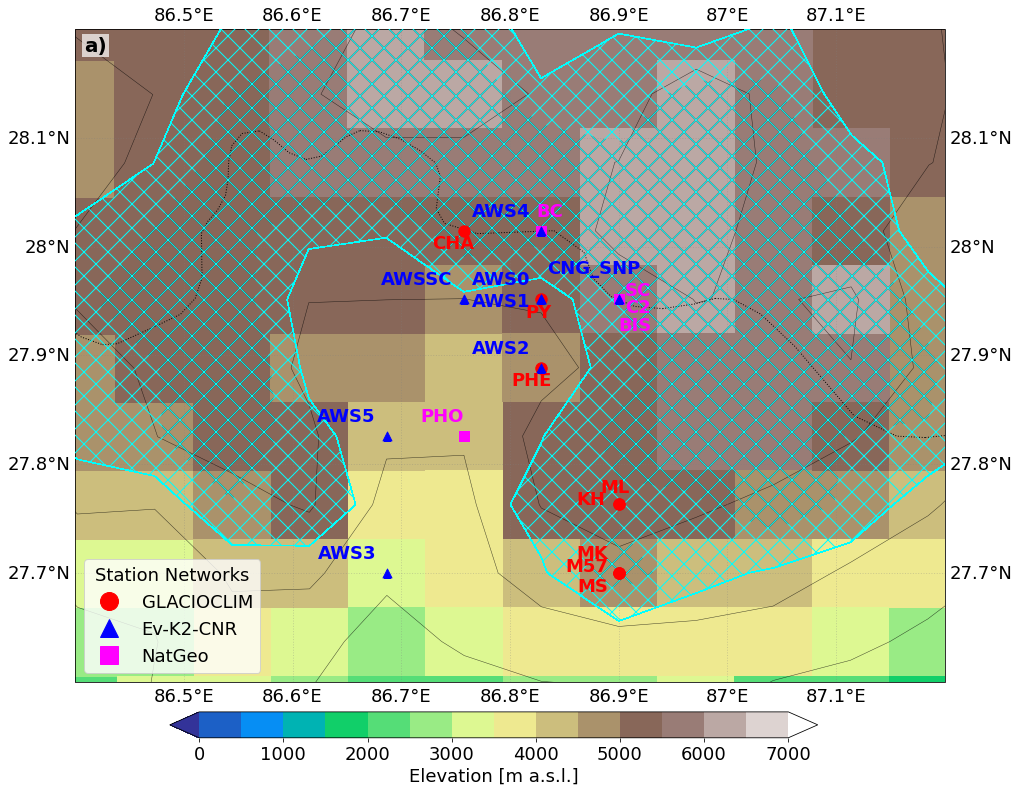

In [12]:

clevs = np.arange(0, 7500, 500)
cmap_mod = plt.get_cmap("terrain")
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap_mod.N, extend="both")

fig, ax = plt.subplots(figsize=(18, 12),
                       subplot_kw={'projection': ccrs.PlateCarree()})

# --- Shading and elevation contours ---
im = ax.pcolormesh(LONS, LATS, dsSH, cmap=cmap_mod, norm=norm,
                   transform=ccrs.PlateCarree(), shading="auto")
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')

# --- ICE overlay ---
ax.contourf(LONS, LATS, dsICE, levels=[10, 50, 100],
            hatches=['', 'X', 'X'], colors="none", transform=ccrs.PlateCarree())

# --- Elevation contours ---
SH1 = ax.contour(LONS, LATS, dsSH,
                 levels=[1000, 2000, 3000, 4000, 5000, 6000, 7000],
                 colors="k", linewidths=0.5, alpha=0.7,
                 transform=ccrs.PlateCarree())
ax.clabel(SH1, inline=True, fontsize=12, fmt="%d")

# --- Glacier mask contour ---
'''
ICE2 = ax.contour(LONS, LATS, dsICE,
                  levels=[50], colors="black", linewidths=2.0,
                  transform=ccrs.PlateCarree())
ax.clabel(ICE2, inline=True, fontsize=14, fmt="%d")
'''
ICE2 = ax.contourf(
    LONS, LATS, dsICE,
    levels=[20, 100],
    hatches=['X', 'X'],     # or ['X','X']
    colors='none',            # no face fill
    transform=ccrs.PlateCarree(),
    zorder=4                  # put hatch on top of pcolormesh
)

# --- Reliable way to force red hatches ---
for coll in ICE2.collections:
    coll.set_edgecolor('cyan')   # hatch color
    coll.set_linewidth(0.6)     # must be >0 for some backends to draw hatch
    coll.set_facecolor('none')  # ensure no fill hides hatch
    # ensure collection stays above main image
    coll.set_zorder(4)
# Add rectangle to ax1


# --- Map extent and gridlines ---
ax.set_extent([86.4, 87.2, 27.6, 28.2], crs=ccrs.PlateCarree())
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                  linewidth=1, color="gray", alpha=0.3, linestyle=":")
gl.xlabel_style = {"size": fz}
gl.ylabel_style = {"size": fz}

# =====================================================
# === STATION PLOTTING SECTION ===
# =====================================================
# Assign colors and markers for each group
group_style = {
    "GLACIOCLIM": {"color": "red",    "marker": "o", "text_offset": (0.01, -0.02), "ha": "right"},
    "Ev-K2-CNR": {"color": "blue",   "marker": "^", "text_offset": (-0.01, 0.01), "ha": "right"},
    "NatGeo":     {"color": "fuchsia", "marker": "s", "text_offset": (0.00, 0.01), "ha": "right"},
}

group_colors = {
   "GLACIOCLIM": "red",
   "Ev-K2-CNR": "blue",
    "NatGeo": "fuchsia"
}
# Loop through all stations
exclude_stations = {"PYG"}
for name, (lat_sta, lon_sta, group) in stations_all.items():
    if name in exclude_stations:
        continue
    style = group_style.get(group, {"color": "grey", "marker": "x", "text_offset": (0.01, 0.01), "ha": "left"})
    color = style["color"]
    marker = style["marker"]
    dx, dy = style["text_offset"]

    j, i = nearest_indices[name]
    lon = LONS[j, i]
    lat = LATS[j, i]
    station_text_offset = {
    "ML": (0.01, 0.008),
    "KH": (-0.012, -0.003),
    "MS": (-0.01, -0.02),
    "M57": (-0.01, -0.002),
    "MK": (-0.01, +0.01),
    "AWS0": (-0.01, 0.01),
    "AWS1": (-0.01, -0.01),
    "BC": (0.02, +0.01),
    "SC": (0.03, +0.00),
    "C2": (0.03, -0.016),
    "BIS": (0.03, -0.032),
  "CNG_SNP": (0.02, +0.02)
     }
    
    # Plot station marker
    if group=='GLACIOCLIM':
        ax.scatter(lon, lat, marker=marker, color=color, s=130, edgecolor=color,
               transform=ccrs.PlateCarree(), zorder=6)
        dx, dy = station_text_offset.get(name, style["text_offset"])
    # Label text with group-specific offset
        ax.text(lon + dx, lat + dy, name,
            fontsize=fz, fontweight="bold",color=color,
            ha=style["ha"], va="bottom",
            transform=ccrs.PlateCarree(), zorder=7)
    elif group=='NatGeo':
        dx, dy = station_text_offset.get(name, style["text_offset"])
        ax.scatter(lon, lat, marker=marker, color=color, s=100, edgecolor=color,
               transform=ccrs.PlateCarree(), zorder=7)

    # Label text with group-specific offset
        ax.text(lon + dx, lat + dy, name,
            fontsize=fz, fontweight="bold",color=color,
            ha=style["ha"], va="bottom",
            transform=ccrs.PlateCarree(), zorder=8)
    else:
        dx, dy = station_text_offset.get(name, style["text_offset"])
        ax.scatter(lon, lat, marker=marker, color=color, s=80, edgecolor=color,
               transform=ccrs.PlateCarree(), zorder=8)

    # Label text with group-specific offset
        ax.text(lon + dx, lat + dy, name,
            fontsize=fz, fontweight="bold",color=color,
            ha=style["ha"], va="bottom",
            transform=ccrs.PlateCarree(), zorder=8)



cbar_ax = fig.add_axes([0.25, 0.06, 0.5, 0.03])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Elevation [m a.s.l.]", fontsize=fz)
cbar.ax.tick_params(labelsize=fz)

# Add legend for station groups
legend_handles = []
for group, style in group_style.items():
    handle = Line2D(
        [0], [0],
        marker=style["marker"],
        linestyle="None",
        markerfacecolor=style["color"],
        markeredgecolor=style["color"],
        markersize=18,
        label=group
    )
    legend_handles.append(handle)
ax.text(
    0.01, 0.99, 'a)',
    transform=ax.transAxes,
    fontsize=20,
    fontweight='bold',
    color='black',
    ha='left',
    va='top',
    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2)
)

ax.legend(
    handles=legend_handles,
    title="Station Networks",
    loc="lower left",
    fontsize=18,
    title_fontsize=18,
    frameon=True
)# =====================================================

#plotname = f"FIG8a_map_all_stations_MAR.{domain}_SH_ICE_nepal_zoom_rev1"
#plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
#print(f" Saved: {plotsDir}{plotname}.png")

plt.show()
